# Quantum vs Classical Randomness
### AstraCode Qiskit Fall Fest 2026 · Project 4: Quantum Random Number Generator

**Our question:** Can you tell quantum random numbers apart from Python's, and what does "quantum" really mean here?

**Team** 

**How to run:** install `matplotlib` and `notebook`, open this file from the `qrng` folder, then choose *Kernel → Restart & Run All*. No IBM account or Qiskit is needed: the quantum data was already collected and saved in `data/`.

In [1]:
import json, math, random
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

DATA = Path("data")
N_QUBITS = 8


def load_bits(path):
    """Read the list of 0/1 bits from one of Person 1's JSON datasets."""
    with open(path) as f:
        return json.load(f)["bits"]


def bits_to_numbers(bits, n_qubits=N_QUBITS):
    """Group bits into n_qubits-sized chunks and read each as a binary number."""
    return [
        int("".join(map(str, bits[i:i + n_qubits])), 2)
        for i in range(0, len(bits) - n_qubits + 1, n_qubits)
    ]


hardware = load_bits(DATA / "quantum_bits_hardware.json")
noisy = load_bits(DATA / "quantum_bits_noisy.json")

# Same amount of classical data; the fixed seed makes the notebook reproducible.
rng = random.Random(2026)
python_bits = [rng.getrandbits(1) for _ in range(len(hardware))]

datasets = {
    "IBM hardware\n(ibm_fez)": hardware,
    "Noisy\nsimulator": noisy,
    "Python\nrandom": python_bits,
}
COLORS = ["#4f46e5", "#f59e0b", "#10b981"]
print({name.replace("\n", " "): len(bits) for name, bits in datasets.items()})

{'IBM hardware (ibm_fez)': 1000, 'Noisy simulator': 1000, 'Python random': 1000}


In [2]:
# Quick check that every dataset only contains 0s and 1s, and how many bits it has.
for name, bits in datasets.items():
    label = name.replace("\n", " ")
    assert set(bits) <= {0, 1}, f"{label} contains values other than 0 and 1"
    print(f"{label:<22} {len(bits)} bits, {sum(bits)} ones")

IBM hardware (ibm_fez) 1000 bits, 512 ones
Noisy simulator        1000 bits, 464 ones
Python random          1000 bits, 523 ones


## The quantum idea in plain language

A normal computer bit is always 0 or 1. A **qubit** can be in a *superposition*: a
blend of 0 and 1 at the same time. When we apply a **Hadamard gate** to a qubit that
starts at 0, it becomes an equal blend: a 50% chance of 0 and a 50% chance of 1.

Then we **measure** it. Measurement forces the qubit to give one answer, either 0 or 1.
Which one is not decided in advance by anything we can look up or calculate. Quantum
theory says only the probabilities (50/50) are fixed; the individual result is
genuinely unpredictable. That unpredictability is the "random" in our generator.

Our circuit puts **8 qubits** through a Hadamard gate and measures them. Each qubit
gives one random bit, so one run gives 8 bits, which we read as a number from
0 to 255. Repeating the run 125 times gives 1,000 bits.

Python's `random` module works differently. It uses a formula (the Mersenne Twister)
that looks random but is completely determined by its starting state. Know the state
and you can predict every number.

We compared three sources: a real IBM quantum computer (`ibm_fez`), a simulator with
realistic noise, and Python's `random`. We were careful to ask not "which one looks
more random?" but "what can we honestly conclude from 1,000 bits?"

## The circuit
Each of the 8 lines is one qubit, starting at 0. The **H** box is a Hadamard gate: it puts that qubit into an equal mix of 0 and 1. The meter symbol at the end is a **measurement**: it forces the qubit to give one answer, 0 or 1. All 8 run side by side, so one run (a "shot") gives 8 bits, which we read as one number from 0 to 255.

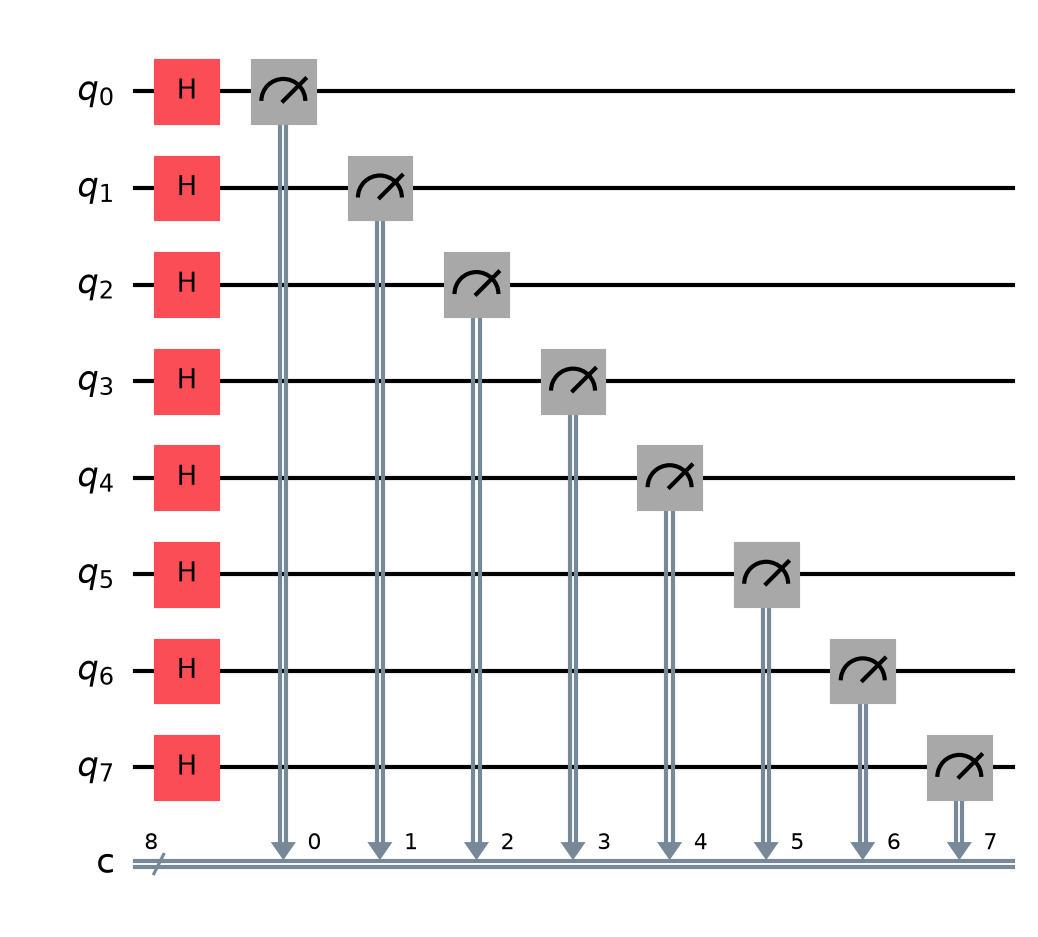

In [3]:
display(Image("circuit_diagram.png"))

## Is each source balanced?
A fair source gives about 50% ones, but never exactly 50%, because chance wobbles. The grey band shows how far a fair source usually wobbles with 1,000 bits. The p-value is the chance of seeing a result this lopsided from a fair source; below 0.05 is unusual.

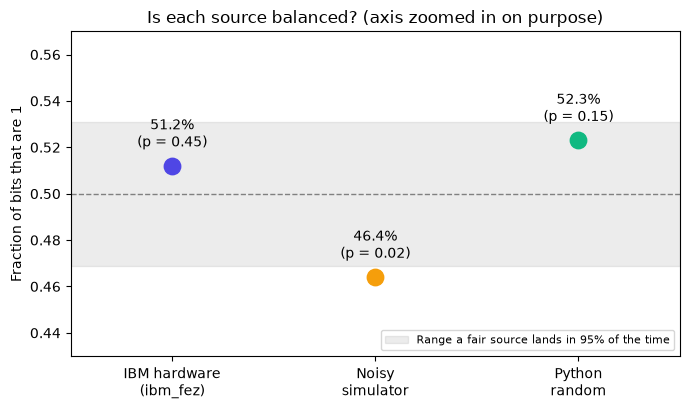

In [7]:
def ones_fraction(bits):
    return sum(bits) / len(bits)


def monobit_p_value(bits):
    """NIST-style frequency test: a small p-value means 0s and 1s are unbalanced."""
    n = len(bits)
    imbalance = abs(sum(2 * b - 1 for b in bits))
    return math.erfc(imbalance / math.sqrt(2 * n))


n = len(hardware)
band = 1.96 * math.sqrt(0.25 / n)  # 95% range for a fair source

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.axhspan(0.5 - band, 0.5 + band, color="grey", alpha=0.15,
           label="Range a fair source lands in 95% of the time")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)

for i, (name, bits) in enumerate(datasets.items()):
    f = ones_fraction(bits)
    ax.scatter(i, f, s=140, color=COLORS[i], zorder=3)
    ax.annotate(f"{f:.1%}\n(p = {monobit_p_value(bits):.2f})", (i, f),
                textcoords="offset points", xytext=(0, 14), ha="center")

ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(list(datasets))
ax.set_ylim(0.43, 0.57)
ax.set_ylabel("Fraction of bits that are 1")
ax.set_title("Is each source balanced? (axis zoomed in on purpose)")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(-0.5, 2.5)
plt.tight_layout()

plt.show()

## Can you tell them apart by eye?
Below are the 125 numbers (0-255) from each source, grouped into 16 buckets. A perfect generator would put the same count in every bucket (dashed line). None of the three looks "more random" than the others.

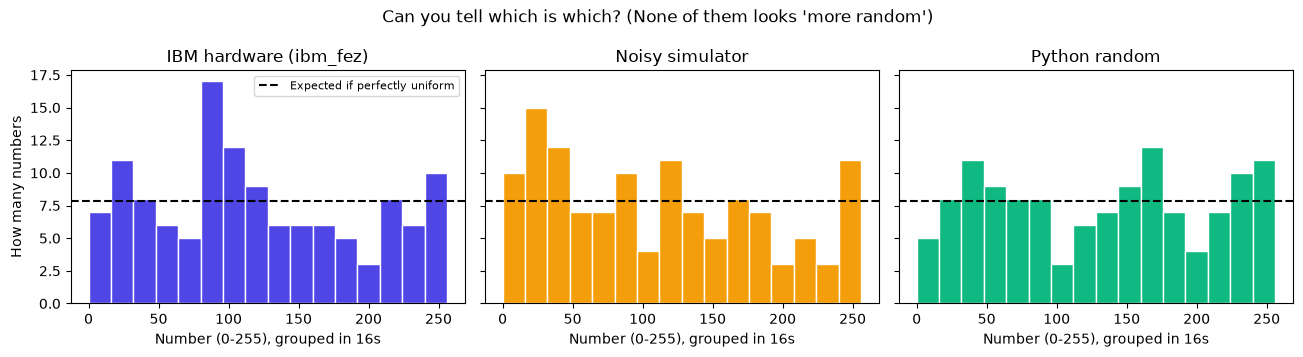

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)

for ax, color, (name, bits) in zip(axes, COLORS, datasets.items()):
    numbers = bits_to_numbers(bits)
    ax.hist(numbers, bins=range(0, 257, 16), color=color, edgecolor="white")
    ax.axhline(len(numbers) / 16, color="black", linestyle="--",
               label="Expected if perfectly uniform")
    ax.set_title(name.replace("\n", " "))
    ax.set_xlabel("Number (0-255), grouped in 16s")

axes[0].set_ylabel("How many numbers")
axes[0].legend(fontsize=8)
fig.suptitle("Can you tell which is which? (None of them looks 'more random')")
plt.tight_layout()
plt.show()

## Statistical tests
(mike's section: counts of 0s and 1s, longest run, and the frequency test.)

## Noise Detective: why is the simulator lopsided?
Our simulator copies a real-world flaw: a qubit holding 1 is sometimes misread as 0 (12% of the time, a number we chose), while 0 is misread as 1 less often (5%). So we predicted a bias before looking at the data.

In [6]:
# Parameters of OUR noise model (chosen by us, not measured from a real device).
P_READ_0_GIVEN_1 = 0.12   # a qubit that is 1 gets misread as 0
P_READ_1_GIVEN_0 = 0.05   # a qubit that is 0 gets misread as 1

expected_ones = 0.5 * (1 - P_READ_0_GIVEN_1) + 0.5 * P_READ_1_GIVEN_0
observed_ones = ones_fraction(noisy)

print(f"Predicted fraction of 1s from the noise model: {expected_ones:.1%}")
print(f"Observed in the noisy simulation:              {observed_ones:.1%}")
print("The bias is explained: 1s are misread as 0 more often than the reverse.")

Predicted fraction of 1s from the noise model: 46.5%
Observed in the noisy simulation:              46.4%
The bias is explained: 1s are misread as 0 more often than the reverse.


## The three questions

**1. Can you tell the quantum results from Python's by looking?**
No. The charts and basic tests can't separate them. Python's generator is designed to look random, and 1,000 bits is too few to expose any pattern. The difference is where the randomness comes from, not how it looks.

**2. What tests could check the numbers look random?**
A frequency test (are 0s and 1s balanced?), a runs test (are streaks the right length?), entropy, and autocorrelation (does one bit predict the next?). Passing means "no flaw found", not "proven random".

**3. How "quantum" is a simulator's randomness?**
Barely. A simulator is a classical program using a classical pseudo-random generator, like Python. Only the hardware run gets its randomness from a physical measurement. Even then, real hardware has small biases.

## What we learned
- Superposition plus measurement gives a bit that no formula can predict.
- With 1,000 bits, real hardware and Python both look like a fair coin; statistics cannot tell them apart.
- Our noisy simulator's bias matched what its readout errors predicted, so noise leaves a fingerprint.
- A simulator is classical; only the hardware run has a physical quantum origin.

**Honest limits:** 1,000 bits is small, we have one hardware run, our noise numbers were chosen rather than measured, and passing tests never proves true randomness.